In [1]:
# Configuration: edit this JSON file, then restart the kernel and Run All.
from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "functions.py").is_file() and (p / "applications/configs").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or applications/ folder")
sys.path.insert(0, str(REPO_ROOT))
from reporting import (load_application_config, repo_path, utc_timestamp,
                       select_analysis_window, select_snapshot_time,
                       capture_summary, export_application_results)
CONFIG_PATH = repo_path(REPO_ROOT, globals().get("CONFIG_PATH", REPO_ROOT / "applications/configs/solo.json"))
config = load_application_config(CONFIG_PATH, "solo", REPO_ROOT)
analysis, plot_config = config["analysis"], config["plot"]
outer_fit_kwargs = {"maxfev": config["outer_fit"]["maxfev"], "Rc_max": config["outer_fit"]["Rc_max_m"]}

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import netCDF4 as nc
import xarray as xr
import scipy.io as sio
from datetime import datetime, timedelta

from functions import plot_outer_core_fit, decode_ce23_mat_time, interpolate_satellite_at_time, solo, project_sadcp_to_transect, translate_solo_results, axis_ratio_from_Q, tangential_velocity, out_core_param_fit, model_uv_at_xy, vector_R2 


### SADCP Data

In [2]:
sad = sio.loadmat(repo_path(REPO_ROOT, config["inputs"]["sadcp"]), simplify_cells=True)

z = sad['z_sadcp']
# CE23-specific UTC correction, applied once; raw MAT values are unchanged.
time = decode_ce23_mat_time(sad['tim_sadcp'])

df = pd.DataFrame({
    "Time": time,
    "raw_index": np.arange(time.size),
    "Lon": sad['lon_sadcp'],
    "Lat": sad['lat_sadcp']
})

df = pd.concat([
    df,
    pd.DataFrame(sad['u_sadcp'], index=[f'u_{zv}' for zv in z]).T,
    pd.DataFrame(sad['v_sadcp'], index=[f'v_{zv}' for zv in z]).T
], axis=1)

df = df[df.Lat <= analysis["latitude_max"]].reset_index(drop=True)

theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
df["x"] = (df.Lon-theta_mean)*111000*np.cos(np.deg2rad(phi_mean))
df["y"] = (df.Lat-phi_mean)*111000

ds_sadcp = xr.Dataset(
    {"u": (("time","z"), df[[f"u_{zz}" for zz in z]].to_numpy()),
     "v": (("time","z"), df[[f"v_{zz}" for zz in z]].to_numpy())},
    coords={
        "time": df.Time.values,
        "raw_index": ("time", df.raw_index.values),
        "z": z,
        "lon": ("time", df.Lon.values),
        "lat": ("time", df.Lat.values),
        "x": ("time", df.x.values),
        "y": ("time", df.y.values),
    }
)

# Configured anchor uses the corrected UTC labels; half-window is unchanged.
t0 = utc_timestamp(analysis["transect_center_utc"])
dt = pd.Timedelta(hours=analysis["half_window_hours"])

ds_sadcp = ds_sadcp.sel(time=(ds_sadcp.time >= t0-dt) & (ds_sadcp.time <= t0+dt)).sel(z=analysis["depth_m"], method="nearest")
if not ds_sadcp.sizes["time"]:
    raise ValueError("Configured SOLO selection is empty")
ds_sadcp


<xarray.Dataset> Size: 6kB
Dimensions:    (time: 96)
Coordinates:
  * time       (time) datetime64[ns] 768B 2023-10-17T01:42:30.666659 ... 2023...
    raw_index  (time) int64 768B 775 776 777 778 779 780 ... 866 867 868 869 870
    z          uint16 2B 37
    lon        (time) float64 768B 154.4 154.4 154.4 154.4 ... 154.5 154.5 154.5
    lat        (time) float64 768B -37.1 -37.1 -37.1 ... -38.76 -38.76 -38.76
    x          (time) float64 768B 7.198e+03 7.399e+03 ... 1.985e+04 1.968e+04
    y          (time) float64 768B 8.831e+04 8.833e+04 ... -9.562e+04 -9.556e+04
Data variables:
    u          (time) float64 768B 0.3383 0.3354 0.3216 ... -0.2969 -0.2948
    v          (time) float64 768B -0.06571 -0.03258 ... 0.006335 0.02006

### Satellite data are not required for the SOLO fit

In [3]:
# No satellite input is used by this SOLO example.


### Approximate ESP parameters using SOLO

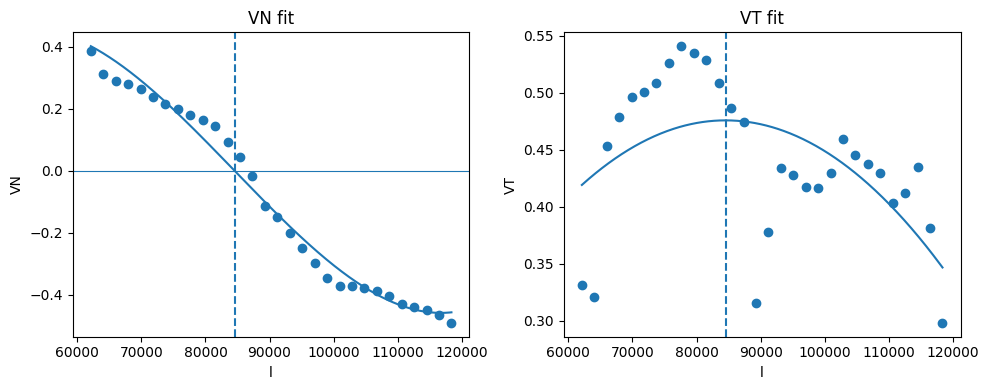

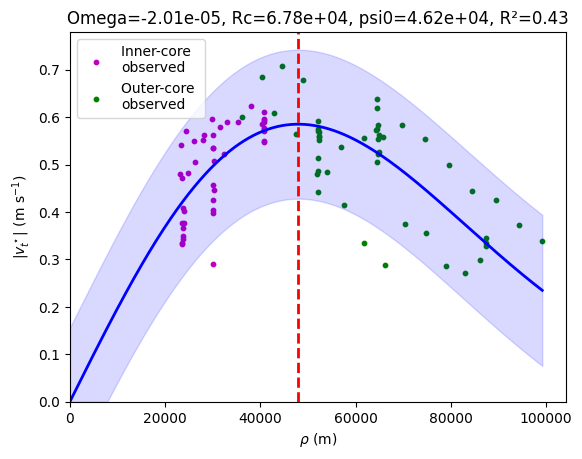

In [4]:
xi, yi, ui, vi = ds_sadcp.x.values, ds_sadcp.y.values, ds_sadcp.u.values, ds_sadcp.v.values

# Project data to transect
df_proj, moca_meta = project_sadcp_to_transect(xi, yi, ui, vi)
# Calculate inner-core ESP parameters
core_thresh = analysis["core_radius_m"]
solo_selection = {}
l0, r0, w, Q, Omega = solo(df_proj.l, df_proj.V_T, df_proj.V_N, plot=plot_config["diagnostics"],
                          selection_details=solo_selection, core_thresh=core_thresh)
# Map the actual along-track fitting window back to the original ADCP points.
l_raw = ((xi - df_proj.iloc[0].x) + moca_meta * (yi - df_proj.iloc[0].y)) / np.sqrt(1 + moca_meta**2)
l_min, l_max = solo_selection["l_bounds"]
core_mask = (l_raw >= l_min) & (l_raw <= l_max)
# Convert transect center coordinates (l0: length along transect, r0: length perpendicular to transect)
# to cartesian coordinates xc, yc
xc, yc = translate_solo_results(df_proj.iloc[0].x, df_proj.iloc[0].y, moca_meta, l0, r0)

# Gather data from beyond the eddy core to estimate outer-core ESP paramters
dx, dy = xi - xc, yi - yc
rho2 = Q[0,0]*dx*dx + 2*Q[1,0]*dx*dy + Q[1,1]*dy*dy
rho_outer = analysis["outer_radius_m"]
outer = rho2 <= rho_outer**2
xi_o, yi_o, ui_o, vi_o = xi[outer], yi[outer], ui[outer], vi[outer]

Omega_core, w_core = Omega, w
outer_fit = {}
Rc, psi0, Omega_opt = out_core_param_fit(
    xi_o, yi_o, ui_o, vi_o, xc, yc, Q, Omega0=Omega, plot=plot_config["diagnostics"],
    km_flag=False, pred_flag=True, fit_details=outer_fit, core_mask=core_mask[outer], **outer_fit_kwargs)

alpha = 1 # calculate axis ratio (assumes axisymmetric)
w = 2.0*Omega_opt # recalculate vorticity with optimal Omega
Omega = Omega_opt

data = {'xc': [xc], 'yc': [yc], 'w': [w], 'Q': [Q], 'alpha': [alpha],
        'Rc': [Rc], 'psi0': [psi0], 'Omega': [Omega],
        'Omega_core': [Omega_core], 'w_core': [w_core], 'fit_status': [outer_fit['status']], 'time': [ds_sadcp.time.mean().values]}
data = pd.DataFrame(data).iloc[0]
df_res = pd.DataFrame(data).T


### Reconstruct the velocity field using the ESP parameters

In [5]:
x = np.linspace(*config["reconstruction"]["x_limits_m"], config["reconstruction"]["grid_points"])
y = np.linspace(*config["reconstruction"]["y_limits_m"], config["reconstruction"]["grid_points"])
X, Y = np.meshgrid(x, y, indexing="xy")

dx, dy = X - data.xc, Y - data.yc
q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]

rho2 = q11*dx*dx + 2*q12*dx*dy + q22*dy*dy

fac = data.Omega * np.exp(-rho2 / data.Rc**2)

U = -fac * (q12*dx + q22*dy)
V =  fac * (q11*dx + q12*dy)

ds_model = xr.Dataset(
    data_vars=dict(
        u=(("y","x"), U),
        v=(("y","x"), V),
    ),
    coords=dict(
        x=("x", x),
        y=("y", y),
        x2d=(("y","x"), X),
        y2d=(("y","x"), Y),
    ),
)

ds_model


<xarray.Dataset> Size: 1MB
Dimensions:  (y: 200, x: 200)
Coordinates:
  * x        (x) float64 2kB -1.5e+05 -1.485e+05 -1.47e+05 ... 1.485e+05 1.5e+05
  * y        (y) float64 2kB -1.5e+05 -1.485e+05 -1.47e+05 ... 1.485e+05 1.5e+05
    x2d      (y, x) float64 320kB -1.5e+05 -1.485e+05 ... 1.485e+05 1.5e+05
    y2d      (y, x) float64 320kB -1.5e+05 -1.5e+05 -1.5e+05 ... 1.5e+05 1.5e+05
Data variables:
    u        (y, x) float64 320kB -0.0002651 -0.0002906 ... 0.0001152 0.0001038
    v        (y, x) float64 320kB 0.0002443 0.0002649 ... -0.0001233 -0.0001122

### Find coefiicient of determination $R^2$ between model and data

In [6]:
df_xyuv = pd.DataFrame({'time': data.time, 'xi': ds_sadcp.x.values, 'yi': ds_sadcp.y.values,
                        'ui': ds_sadcp.u.values, 'vi': ds_sadcp.v.values})

# Find R2
row = df_res.iloc[0]
df = df_xyuv[df_xyuv.time == row.time]
xi = df.xi.to_numpy(float)
yi = df.yi.to_numpy(float)
u  = df.ui.to_numpy(float)
v  = df.vi.to_numpy(float)
uhat, vhat = model_uv_at_xy(xi, yi, row.xc, row.yc, np.asarray(row.Q), row.Omega, row.Rc)
df_res['R2'] = vector_R2(u, v, uhat, vhat)


### Plot results

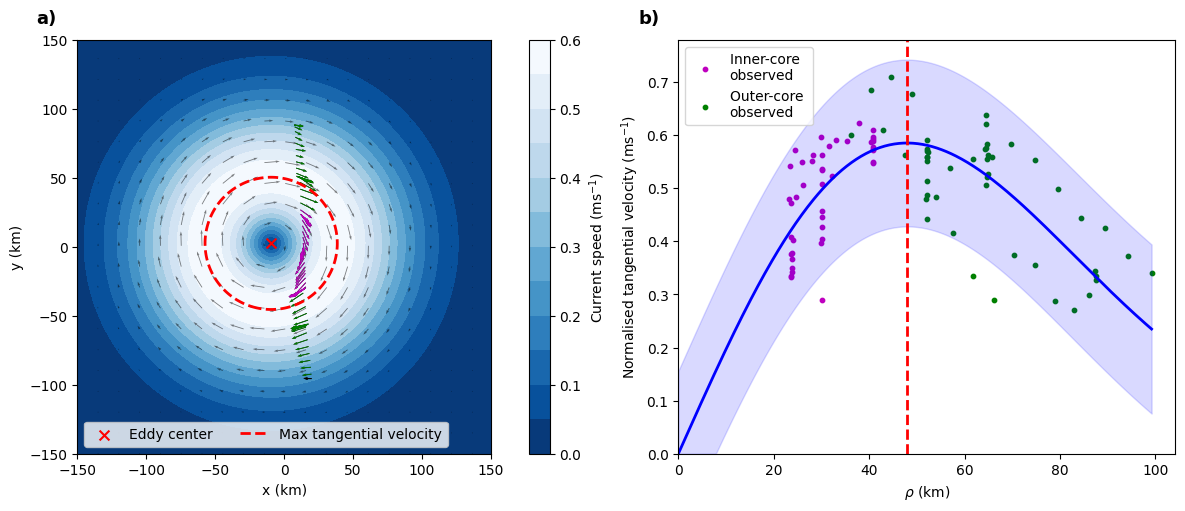

In [7]:
if outer_fit["status"] != "optimized":
    print("SOLO Gaussian figure unavailable: " + outer_fit["status"])
else:
    u = ds_model.u
    v = ds_model.v
    speed = np.hypot(u, v)

    # 1D km coords for plotting
    x = (ds_model.x / 1e3).values
    y = (ds_model.y / 1e3).values

    xmin, xmax = plot_config["x_limits_km"]
    ymin, ymax = plot_config["y_limits_km"]

    # 2D ROI mask (ny, nx)
    Xkm, Ykm = np.meshgrid(x, y, indexing="xy")
    roi = (Xkm >= xmin) & (Xkm <= xmax) & (Ykm >= ymin) & (Ykm <= ymax)

    speed_m = speed.where(roi)

    vmin = float(speed_m.min(skipna=True))
    vmax = float(speed_m.max(skipna=True))
    levels = np.arange(0, vmax+.05, .05)

    fig, axs = plt.subplots(1, 2, figsize=(12,5), constrained_layout=True)

    ax = axs[0]

    # field first (so vectors on top)
    cf = ax.contourf(x, y, speed_m.values, levels=levels, cmap="Blues_r", vmin=vmin, vmax=vmax, zorder=-1)
    fig.colorbar(cf, ax=ax, label=r"Current speed (ms$^{-1}$)")

    spac, scale = plot_config["quiver_spacing"], plot_config["quiver_scale"]
    ax.quiver(x[::spac], y[::spac],
                  u[::spac,::spac], v[::spac,::spac],
                  scale=scale, alpha=.5, width=.002)

    # SADCP vectors (x,y already metres -> convert to km; u,v are m/s)
    ax.quiver(ds_sadcp.x.values/1e3, ds_sadcp.y.values/1e3,
              ds_sadcp.u.values, ds_sadcp.v.values,
              width=.002, scale=scale)

    R = np.hypot(data.xc - ds_sadcp.x.values, data.yc - ds_sadcp.y.values)

    # Reuse the original along-track core window and outer selection.
    outer_mask = outer & ~core_mask

    ax.quiver(ds_sadcp.x.values[core_mask]/1e3, ds_sadcp.y.values[core_mask]/1e3,
              ds_sadcp.u.values[core_mask], ds_sadcp.v.values[core_mask],
              width=.002, scale=scale, color='m')#, label='Core data')

    ax.quiver(ds_sadcp.x.values[outer_mask]/1e3, ds_sadcp.y.values[outer_mask]/1e3,
              ds_sadcp.u.values[outer_mask], ds_sadcp.v.values[outer_mask],
              width=.002, scale=scale, color='g')#, label='Outer-core \ndata') 

    # center
    ax.scatter(xc/1e3, yc/1e3, marker="x", color="r", s=50, label='Eddy center')

    # ellipse contour: compute in metres, but evaluate on the km grid
    Xm = Xkm * 1e3
    Ym = Ykm * 1e3
    dx = Xm - xc
    dy = Ym - yc
    rho2 = Q[0,0]*dx*dx + 2*Q[0,1]*dx*dy + Q[1,1]*dy*dy

    ax.contour(x, y, rho2, levels=[(Rc**2)/2], colors="r", linewidths=2, linestyles='--')
    ax.plot([np.nan, np.nan], [np.nan, np.nan], color='r', ls='--', lw=2, label='Max tangential velocity')

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.legend(loc='lower left', ncol=2)
    ax.text(-0.10, 1.04, 'a)', transform=ax.transAxes, fontsize=13, fontweight='bold')

    ax = axs[1]
    plot_outer_core_fit(outer_fit, ax=ax, km_flag=True, pred_flag=True)

    ax.set_title(''); ax.set_xlabel(r'$\rho$ (km)'); ax.set_ylabel(r'Normalised tangential velocity (ms$^{-1}$)');
    ax.text(-0.08, 1.04, 'b)', transform=ax.transAxes, fontsize=13, fontweight='bold')

    plt.show()


In [8]:
# Results
df_res


,xc,yc,w,Q,alpha,Rc,psi0,Omega,Omega_core,w_core,fit_status,time,R2
0,-9434.639872,2507.191389,-0.00004,"[[1.0, 0.0], [0.0, 1.0]]",1,67805.107217,46249.479018,-0.00002,-0.000021,-0.000043,optimized,2023-10-17 13:35:00.562501250,0.948525


### Manuscript results summary
Computed from this run. All dates are UTC; final refined parameters are reported.
This notebook demonstrates ESP on real data; idealised experiments are outside its scope.

In [9]:
with capture_summary() as manuscript_text:
    from reporting import print_manuscript_summary, fit_record, evaluation_counts

    summary_counts = pd.DataFrame([{
        "source": "sadcp", "original_observations": ds_sadcp.sizes["time"],
        "resampled_transect_points": len(df_proj),
        "resampled_inner_fit_points": int(solo_selection["core_mask"].sum()),
        "original_points_in_core_window": int(core_mask.sum()),
        "outer_candidates": int(outer.sum()), "outer_fit_n": len(outer_fit["rho"]),
        "velocity_R2_n": int(evaluation_counts(df_xyuv).velocity_R2_n.sum()),
    }])
    print_manuscript_summary(
        "SOLO — S-ADCP", df_res.assign(source="sadcp"),
        {"Original observation interval": f"{ds_sadcp.time.values[0]} to {ds_sadcp.time.values[-1]} UTC",
         "Observation duration (hours)": (ds_sadcp.time.values[-1] - ds_sadcp.time.values[0]) / np.timedelta64(1, "h"),
         "Mean observation time": f"{ds_sadcp.time.mean().values} UTC",
         "Selection anchor / half-window": f"{t0} UTC / {dt}",
         "Depth (m)": float(ds_sadcp.z),
         "MAT UTC correction": "-12 h, applied once to MAT-derived labels",
         "Local origin (longitude, latitude)": (theta_mean, phi_mean),
         "Inner along-track half-width (km)": core_thresh / 1000,
         "Outer elliptical radius limit (km)": rho_outer / 1000},
        counts=summary_counts,
        outer_records=[fit_record(df_res.iloc[0].time, outer_fit, "sadcp")],
        notes=["Velocity R² uses all original selected ADCP pairs, not just the outer fit.",
               "The inner fit uses resampled transect points; original-point colour counts are different.",
               "Shading is an approximate 95% prediction interval; space/time correlation is ignored."],
        input_files=["applications/SOLO_transect_data.ipynb", *config["inputs"].values()], root=REPO_ROOT)

export_directory = export_application_results(
    REPO_ROOT, CONFIG_PATH, config,
    df_res, manuscript_text.getvalue(),
    notebook="applications/SOLO_transect_data.ipynb",
    tables={"observation_counts": summary_counts, "outer_fit_diagnostics": pd.DataFrame([fit_record(df_res.iloc[0].time, outer_fit, "sadcp")])},
    run_info={"raw_adcp_indices": ds_sadcp.raw_index.values, "mean_adcp_time_utc": ds_sadcp.time.mean().values})



MANUSCRIPT RESULTS SUMMARY — SOLO — S-ADCP
Current run; compare with the manuscript after any analysis change. All times UTC.

DATA AND SETTINGS
  Original observation interval: 2023-10-17T01:42:30.666659000 to 2023-10-18T01:27:30.333340000 UTC
  Observation duration (hours): 23.74990741138889
  Mean observation time: 2023-10-17T13:35:00.562501250 UTC
  Selection anchor / half-window: 2023-10-17 13:30:00 UTC / 0 days 12:00:00
  Depth (m): 37.0
  MAT UTC correction: -12 h, applied once to MAT-derived labels
  Local origin (longitude, latitude): (154.3, -37.9)
  Inner along-track half-width (km): 30.0
  Outer elliptical radius limit (km): 100.0

MANUSCRIPT-ROUNDED VALUES (final refined Omega; omega = Omega tr(Q))
  sadcp, 2023-10-17 13:35:00.562501250 UTC: (x0,y0)=(-9.4, 2.5) km; omega=-4.0e-05 s^-1; Omega=-2.0e-05 s^-1; alpha=1.00; Rc=67.8 km; psi0=46249.5 m^2/s; R²_velocity=0.95

NUMERICAL RESULTS (additional precision, not physical measurement accuracy)
source                        